# Pinocchio: analytic Jacobians and frame accelerations

**Chapter 5 · Lecture L4 · Slide 24 and slides 26–27**

This notebook turns the slide formulas into runnable Pinocchio calls. It uses a three-joint spatial arm and a rotating one-metre link. Both models are built here, so no URDF, meshes, downloads, or robot hardware are needed.

1. [Slide 24: analytic Jacobians](#analytic-jacobians): retrieve `LOCAL`, `WORLD`, and `LOCAL_WORLD_ALIGNED` Jacobians, then convert to orientation-coordinate rates.
2. [Slides 26–27: accelerations](#accelerations): retrieve spatial and classical accelerations, and verify the transport and Jacobian formulas.
3. [One-link example](#one-link-example): zero spatial acceleration with nonzero centripetal acceleration.

**Run all cells in order.** From the repository root, install `requirements-kinematics.txt` in the selected Python environment. The pip distribution is **pin**; the import is **pinocchio**. GitHub displays the saved outputs but does not execute the cells.

**Conventions.** The world frame is fixed and inertial. The body/tool frame moves with the robot. $T_{sb}=(R,p)$ maps body coordinates to world coordinates. Motion is relative to the world even when expressed in body axes. Six-vectors use **linear first**, $(v,\omega)$. Lengths are in metres and angles in radians. These revolute-joint models have $n_q=n_v$, so the generalized velocity `v` is $\dot q$, and `a` is $\ddot q$.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

try:
    import pinocchio as pin
except ModuleNotFoundError as error:
    if error.name != "pinocchio":
        raise
    # Some notebook launchers skip the pip wheel's cmeel startup hook.
    import cmeel_pth
    import pinocchio as pin

np.set_printoptions(precision=6, suppress=True, linewidth=100)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
print("Pinocchio", pin.__version__, "| NumPy", np.__version__)

Pinocchio 3.9.0 | NumPy 2.3.5


## A spatial arm with three revolute joints

The joint axes are local $z$, $y$, and $x$, respectively. The relative joint-origin offsets are $(0,0,0.25)$, $(0.65,0,0)$, and $(0.5,0,0)$ m. The tool is offset by $(0.35,0.12,0.05)$ m from the last joint. All fixed mounting rotations are identity.

Consequently, the tool orientation is $R=R_z(q_1)R_y(q_2)R_x(q_3)$. This makes the roll–pitch–yaw coordinates particularly easy to check: $\chi=(q_3,q_2,q_1)$ in the chart used below. The physical angular-velocity components will still differ from these coordinate rates.

`model` stores the robot structure; `data` is mutable workspace. Copy quantities that must survive another algorithm call.

In [2]:
model = pin.Model()
parent = 0
joint_ids = []
joint_models = [pin.JointModelRZ(), pin.JointModelRY(), pin.JointModelRX()]
offsets = [[0., 0., .25], [.65, 0., 0.], [.5, 0., 0.]]
for i, (joint_model, offset) in enumerate(zip(joint_models, offsets), start=1):
    placement = pin.SE3(np.eye(3), np.array(offset))
    parent = model.addJoint(parent, joint_model, placement, f"joint_{i}")
    joint_ids.append(parent)

tool_mount = pin.SE3(np.eye(3), np.array([.35, .12, .05]))
fid = model.addFrame(pin.Frame("tool", parent, tool_mount, pin.FrameType.OP_FRAME))
data = model.createData()
q = np.array([.45, -.55, .35])       # rad
v = np.array([.7, -.4, .5])         # rad/s
a = np.array([.2, .3, -.1])         # rad/s^2

pin.forwardKinematics(model, data, q)
pin.updateFramePlacements(model, data)
T = data.oMf[fid].copy()
R, p = T.rotation.copy(), T.translation.copy()
print("nq =", model.nq, "| nv =", model.nv, "| tool frame id =", fid)
print("q =", q, "\nv =", v, "\na =", a)
print("Tool origin p (world, m):", p)
print("Tool orientation R:\n", R)

nq = 3 | nv = 3 | tool frame id = 1
q = [ 0.45 -0.55  0.35] 
v = [ 0.7 -0.4  0.5] 
a = [ 0.2  0.3 -0.1]
Tool origin p (world, m): [1.15475  0.663955 0.769406]
Tool orientation R:
 [[ 0.767653 -0.56998  -0.292969]
 [ 0.370819  0.767897 -0.522329]
 [ 0.522687  0.292329  0.800838]]


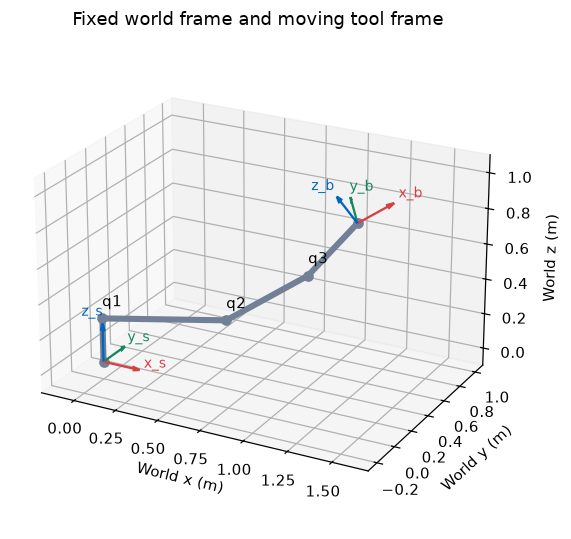

In [3]:
def draw_frame(ax, origin, rotation, name, length=.22):
    for j, (axis, color) in enumerate(zip("xyz", ["#D64045", "#16865C", "#0065BD"])):
        direction = length * rotation[:, j]
        ax.quiver(*origin, *direction, color=color, arrow_length_ratio=.2)
        ax.text(*(origin + 1.12 * direction), f"{axis}_{name}", color=color, fontsize=9,
                ha="right" if j == 2 else "left", va="bottom")

points = np.vstack([np.zeros(3)] + [data.oMi[j].translation.copy() for j in joint_ids] + [p])
fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection="3d")
ax.plot(*points.T, "o-", color="#718096", linewidth=4, markersize=6)
for j, point in enumerate(points[1:-1], start=1):
    ax.text(*(point + [0, 0, .07]), f"q{j}", fontsize=10)
draw_frame(ax, np.zeros(3), np.eye(3), "s")
draw_frame(ax, p, R, "b")
ax.set(xlabel="World x (m)", ylabel="World y (m)", zlabel="World z (m)",
       xlim=(-.2, 1.7), ylim=(-.3, 1.1), zlim=(-.1, 1.1),
       title="Fixed world frame and moving tool frame")
ax.set_box_aspect((1.9, 1.4, 1.2))
ax.view_init(elev=23, azim=-62)
fig.tight_layout()
plt.show()

<a id="slide-24-analytic-jacobians"></a>
<a id="analytic-jacobians"></a>
## Slide 24: analytic Jacobians

### Retrieve the geometric Jacobians

The three calls below use the same robot configuration. They differ in the axes and reference origin of the returned twist:

| Pinocchio convention | Output when multiplied by $v$ |
|---|---|
| `LOCAL` | $\mathcal V_b=(R^T\dot p,\omega_b)$ |
| `WORLD` | $\mathcal V_s=(\dot p-\omega_s\times p,\omega_s)$ |
| `LOCAL_WORLD_ALIGNED` | $\mathcal V_{\rm LWA}=(\dot p,\omega_s)$ |

Compute joint Jacobians, update frame placements, then retrieve the Jacobian for the **tool frame id**. A frame id and a joint id are different indices.

In [4]:
pin.computeJointJacobians(model, data, q)
pin.updateFramePlacements(model, data)
J_b = pin.getFrameJacobian(model, data, fid, pin.LOCAL).copy()
J_s = pin.getFrameJacobian(model, data, fid, pin.WORLD).copy()
J_lwa = pin.getFrameJacobian(model, data, fid, pin.LOCAL_WORLD_ALIGNED).copy()

for name, J in [("LOCAL: J_b", J_b), ("WORLD: J_s", J_s), ("LWA: J_lwa", J_lwa)]:
    print(name, "\n", J, "\n")

V_b, V_s, V_lwa = J_b @ v, J_s @ v, J_lwa @ v
p_dot, omega_s = V_lwa[:3], V_lwa[3:]
np.testing.assert_allclose(J_s, T.action @ J_b, atol=1e-12)
np.testing.assert_allclose(J_lwa[:3], R @ J_b[:3], atol=1e-12)
np.testing.assert_allclose(J_lwa[:3], J_s[:3] - pin.skew(p) @ J_s[3:], atol=1e-12)
print("Tool-origin velocity in world axes:", p_dot)
print("Spatial twist linear block:       ", V_s[:3])

LOCAL: J_b 
 [[-0.081484  0.088116 -0.      ]
 [ 1.26517  -0.291463 -0.05    ]
 [-0.408641 -0.798467  0.12    ]
 [ 0.522687  0.        1.      ]
 [ 0.292329  0.939373  0.      ]
 [ 0.800838 -0.342898  0.      ]] 

WORLD: J_s 
 [[ 0.       -0.225112  0.055073]
 [ 0.       -0.108741 -0.114011]
 [ 0.        0.65     -0.      ]
 [ 0.       -0.434966  0.767653]
 [ 0.        0.900447  0.370819]
 [ 1.        0.        0.522687]] 

LWA: J_lwa 
 [[-0.663955  0.467697 -0.006657]
 [ 1.15475   0.225923 -0.101074]
 [ 0.       -0.678589  0.081484]
 [ 0.       -0.434966  0.767653]
 [ 0.        0.900447  0.370819]
 [ 1.        0.        0.522687]] 

Tool-origin velocity in world axes: [-0.655176  0.667418  0.312177]
Spatial twist linear block:        [ 0.117581 -0.013509 -0.26    ]


### Convert to an analytic Jacobian

Pinocchio's frame-Jacobian calls return geometric Jacobians. To obtain $J_{\rm a}$ for chosen orientation coordinates $\chi$, we convert the angular rows:
$$
\begin{bmatrix}\dot p\\\dot\chi\end{bmatrix}=J_{\rm a}v,
\qquad \omega_s=E_s(\chi)\dot\chi.
$$
For roll–pitch–yaw, `pin.rpy.computeRpyJacobian(chi, pin.WORLD)` returns $E_s$. Pinocchio uses $R=R_z(\mathrm{yaw})R_y(\mathrm{pitch})R_x(\mathrm{roll})$.

The three formulas on slide 24 are
$$
J_{\rm a}=\begin{bmatrix}I&0\\0&E_s^{-1}\end{bmatrix}J_{\rm LWA}
=\begin{bmatrix}I&-p^\wedge\\0&E_s^{-1}\end{bmatrix}J_s
=\begin{bmatrix}R&0\\0&E_s^{-1}R\end{bmatrix}J_b.
$$
Use a linear solve rather than forming $E_s^{-1}$. This conversion requires a nonsingular coordinate chart. For roll–pitch–yaw, $E_s$ loses rank at pitch $=\pm\pi/2$.

In [5]:
chi = pin.rpy.matrixToRpy(R)
E_s = pin.rpy.computeRpyJacobian(chi, pin.WORLD)
assert np.linalg.cond(E_s) < 10  # This worked example stays well away from gimbal lock.

J_a_lwa = np.vstack((J_lwa[:3], np.linalg.solve(E_s, J_lwa[3:])))
J_a_s = np.vstack((J_s[:3] - pin.skew(p) @ J_s[3:],
                   np.linalg.solve(E_s, J_s[3:])))
J_a_b = np.vstack((R @ J_b[:3], np.linalg.solve(E_s, R @ J_b[3:])))
np.testing.assert_allclose(J_a_lwa, J_a_s, atol=1e-12)
np.testing.assert_allclose(J_a_lwa, J_a_b, atol=1e-12)
np.testing.assert_allclose(J_a_lwa[3:], [[0, 0, 1], [0, 1, 0], [1, 0, 0]], atol=1e-12)

chi_dot = J_a_lwa[3:] @ v
np.testing.assert_allclose(E_s @ chi_dot, omega_s, atol=1e-12)
print("chi = (roll, pitch, yaw):", chi)
print("E_s:\n", E_s)
print("J_a (all three conversions agree):\n", J_a_lwa)
print("Orientation-coordinate rates chi_dot:", chi_dot)
print("Angular velocity omega_s:             ", omega_s)

chi = (roll, pitch, yaw): [ 0.35 -0.55  0.45]
E_s:
 [[ 0.767653 -0.434966  0.      ]
 [ 0.370819  0.900447  0.      ]
 [ 0.522687  0.        1.      ]]
J_a (all three conversions agree):
 [[-0.663955  0.467697 -0.006657]
 [ 1.15475   0.225923 -0.101074]
 [ 0.       -0.678589  0.081484]
 [ 0.        0.        1.      ]
 [ 0.        1.       -0.      ]
 [ 1.        0.       -0.      ]]
Orientation-coordinate rates chi_dot: [ 0.5 -0.4  0.7]
Angular velocity omega_s:              [ 0.557813 -0.174769  0.961344]


### Check against forward kinematics

Perturb each joint coordinate, recompute the pose, and differentiate $(p,\chi)$ numerically. The chosen configuration is away from both gimbal lock and angle cuts, so ordinary central differences are appropriate here. The helper uses fresh `data` and does not overwrite our saved state.

In [6]:
def pose_at(q_value):
    scratch = model.createData()
    pin.forwardKinematics(model, scratch, q_value)
    pin.updateFramePlacements(model, scratch)
    return scratch.oMf[fid].copy()

def pose_coordinates(q_value, representation="rpy"):
    pose = pose_at(q_value)
    orient = (pin.rpy.matrixToRpy(pose.rotation) if representation == "rpy"
              else pin.log3(pose.rotation))
    return np.r_[pose.translation, orient]

def coordinate_jacobian_fd(representation, h=1e-6):
    columns = []
    for direction in np.eye(model.nv):
        plus = pin.integrate(model, q, h * direction)
        minus = pin.integrate(model, q, -h * direction)
        columns.append((pose_coordinates(plus, representation)
                        - pose_coordinates(minus, representation)) / (2 * h))
    return np.column_stack(columns)

J_a_fd = coordinate_jacobian_fd("rpy")
np.testing.assert_allclose(J_a_lwa, J_a_fd, atol=2e-9, rtol=0)
print("Maximum analytic-Jacobian / finite-difference error:",
      np.max(np.abs(J_a_lwa - J_a_fd)))

Maximum analytic-Jacobian / finite-difference error: 8.22666379463044e-11


### The same conversion with a rotation vector

For $R=\operatorname{Exp}(\theta)$, use $E_s(\theta)=J_l(\theta)$ from L3 in the analytic-Jacobian conversion of slide 24. Pinocchio's `Jexp3(theta)` uses the **right/body** exponential differential, $\omega_b=J_r(\theta)\dot\theta$. Hence we can compute
$$
E_s=R\,\texttt{Jexp3}(\theta)=J_l(\theta)=\texttt{Jexp3}(-\theta).
$$
The coordinate-rate vector changes with the chosen representation; the physical angular velocity is the same. Here `log3` is evaluated away from its principal-branch cut at angle $\pi$.

In [7]:
theta = pin.log3(R)
E_s_rotvec = R @ pin.Jexp3(theta)
np.testing.assert_allclose(E_s_rotvec, pin.Jexp3(-theta), atol=1e-12)
J_a_rotvec = np.vstack((J_lwa[:3], np.linalg.solve(E_s_rotvec, J_lwa[3:])))
theta_dot = J_a_rotvec[3:] @ v
np.testing.assert_allclose(J_a_rotvec, coordinate_jacobian_fd("rotvec"), atol=2e-9, rtol=0)
np.testing.assert_allclose(E_s_rotvec @ theta_dot, omega_s, atol=1e-12)
print("Rotation vector theta:", theta)
print("Rotation-vector rate: ", theta_dot)
print("Recovered omega_s:    ", E_s_rotvec @ theta_dot)

Rotation vector theta: [ 0.459357 -0.459921  0.530484]
Rotation-vector rate:  [ 0.732208 -0.124384  0.854014]
Recovered omega_s:     [ 0.557813 -0.174769  0.961344]


<a id="slides-25-26-accelerations"></a>
<a id="accelerations"></a>
## Slides 26–27: accelerations

### Retrieve spatial and classical acceleration

First compute $J$ and $\dot J$ with `computeJointJacobiansTimeVariation`. Then call `forwardKinematics(model, data, q, v, a)` and update the frame placements before querying accelerations. The last call includes the desired generalized acceleration `a`.

`getFrameAcceleration` returns **spatial acceleration**, whereas `getFrameClassicalAcceleration(..., LOCAL_WORLD_ALIGNED)` returns the tool-origin classical acceleration in its linear block and world angular acceleration in its angular block. `WORLD` alone selects a different reference origin; its linear block should not be used as the tool-origin acceleration.

In [8]:
conventions = {"LOCAL": pin.LOCAL, "WORLD": pin.WORLD,
               "LWA": pin.LOCAL_WORLD_ALIGNED}
pin.computeJointJacobiansTimeVariation(model, data, q, v)
pin.updateFramePlacements(model, data)
J = {name: pin.getFrameJacobian(model, data, fid, rf).copy()
     for name, rf in conventions.items()}
dJ = {name: pin.getFrameJacobianTimeVariation(model, data, fid, rf).copy()
      for name, rf in conventions.items()}

# Refresh the state with the requested acceleration after computing dJ.
pin.forwardKinematics(model, data, q, v, a)
pin.updateFramePlacements(model, data)
velocity = {name: pin.getFrameVelocity(model, data, fid, rf).copy()
            for name, rf in conventions.items()}
spatial_acc = {name: pin.getFrameAcceleration(model, data, fid, rf).copy()
               for name, rf in conventions.items()}
classical_lwa = pin.getFrameClassicalAcceleration(
    model, data, fid, pin.LOCAL_WORLD_ALIGNED).copy()
classical_b = pin.getFrameClassicalAcceleration(model, data, fid, pin.LOCAL).copy()

for name in conventions:
    print(f"{name:5s} spatial acceleration:", spatial_acc[name].vector)
print("LWA classical acceleration: ", classical_lwa.vector)

LOCAL spatial acceleration: [ 0.031303  0.036519 -0.772216  0.243244  0.638967  0.005378]
WORLD spatial acceleration: [-0.004011 -0.062242  0.195    -0.179047  0.578051  0.318236]
LWA   spatial acceleration: [ 0.22945   0.443001 -0.591383 -0.179047  0.578051  0.318236]
LWA classical acceleration:  [-0.466727 -0.360985 -0.333594 -0.179047  0.578051  0.318236]


### Verify the formulas on the slides

At the fixed world origin,
$$
\mathcal A_s=\dot{\mathcal V}_s=J_s a+\dot J_s v
=\begin{bmatrix}a_s\\\alpha_s\end{bmatrix},\qquad
\ddot p=a_s+\alpha_s\times p+\omega_s\times\dot p.
$$
For the body convention, $\mathcal A_b=\dot{\mathcal V}_b=J_ba+\dot J_bv$, and
$$
R^T\ddot p=a_b+\omega_b\times v_b.
$$
For LWA the ordinary derivative of the six-vector is already classical:
$$
\frac{d}{dt}\begin{bmatrix}\dot p\\\omega_s\end{bmatrix}
=J_{\rm LWA}a+\dot J_{\rm LWA}v
=\begin{bmatrix}\ddot p\\\alpha_s\end{bmatrix}.
$$
**This LWA derivative differs from the spatial-acceleration API output.** If $a_{\rm LWA}$ denotes the linear block of `getFrameAcceleration(..., LOCAL_WORLD_ALIGNED)`, then
$$
\ddot p=a_{\rm LWA}+\omega_s\times\dot p.
$$
This correction is exactly what `getFrameClassicalAcceleration` adds. The distinction arises because the LWA reference origin moves with the tool, although its axes remain parallel to the world axes.

In [9]:
A_s = spatial_acc["WORLD"]
A_b = spatial_acc["LOCAL"]
A_lwa = spatial_acc["LWA"]
V_b = velocity["LOCAL"]
p_dot = velocity["LWA"].linear.copy()
omega_s = velocity["LWA"].angular.copy()
alpha_s = A_s.angular.copy()

np.testing.assert_allclose(A_s.vector, J["WORLD"] @ a + dJ["WORLD"] @ v, atol=1e-12)
np.testing.assert_allclose(A_b.vector, J["LOCAL"] @ a + dJ["LOCAL"] @ v, atol=1e-12)
ordinary_lwa_derivative = J["LWA"] @ a + dJ["LWA"] @ v
np.testing.assert_allclose(ordinary_lwa_derivative, classical_lwa.vector, atol=1e-12)

p_ddot_from_world = A_s.linear + np.cross(alpha_s, p) + np.cross(omega_s, p_dot)
p_ddot_from_lwa = A_lwa.linear + np.cross(omega_s, p_dot)
p_ddot_from_body = R @ (A_b.linear + np.cross(V_b.angular, V_b.linear))
for result in [p_ddot_from_world, p_ddot_from_lwa, p_ddot_from_body,
               ordinary_lwa_derivative[:3]]:
    np.testing.assert_allclose(result, classical_lwa.linear, atol=1e-12)
np.testing.assert_allclose(classical_b.linear, R.T @ classical_lwa.linear, atol=1e-12)
assert np.linalg.norm(A_lwa.linear - classical_lwa.linear) > .1

print("Tool-origin acceleration (world axes, m/s^2)")
for name, result in [("Classical API", classical_lwa.linear),
                     ("Recovered from WORLD", p_ddot_from_world),
                     ("Recovered from LOCAL", p_ddot_from_body),
                     ("Recovered from LWA", p_ddot_from_lwa),
                     ("J_LWA a + dJ_LWA v", ordinary_lwa_derivative[:3])]:
    print(f"{name:24s}", result)
print("Spatial LWA linear block:", A_lwa.linear)
print("Correction omega x p_dot:", np.cross(omega_s, p_dot))

Tool-origin acceleration (world axes, m/s^2)
Classical API            [-0.466727 -0.360985 -0.333594]
Recovered from WORLD     [-0.466727 -0.360985 -0.333594]
Recovered from LOCAL     [-0.466727 -0.360985 -0.333594]
Recovered from LWA       [-0.466727 -0.360985 -0.333594]
J_LWA a + dJ_LWA v       [-0.466727 -0.360985 -0.333594]
Spatial LWA linear block: [ 0.22945   0.443001 -0.591383]
Correction omega x p_dot: [-0.696177 -0.803986  0.25779 ]


### Independently differentiate a short trajectory

For these scalar joints, use $q(t)=q+tv+\tfrac12t^2a$ and $v(t)=v+ta$. The second difference of the tool position checks the physical acceleration without using $\dot J$. The first differences of the spatial/body twists check their acceleration conventions. Fresh `data` keeps these samples separate from the worked state.

In [10]:
def sample_state(t):
    scratch = model.createData()
    q_t = pin.integrate(model, q, t * v + .5 * t**2 * a)
    v_t = v + t * a
    pin.forwardKinematics(model, scratch, q_t, v_t)
    pin.updateFramePlacements(model, scratch)
    pose = scratch.oMf[fid].copy()
    twists = {name: pin.getFrameVelocity(model, scratch, fid, rf).vector.copy()
              for name, rf in conventions.items()}
    return pose.translation.copy(), twists

h = 1e-4
p_plus, V_plus = sample_state(h)
p_minus, V_minus = sample_state(-h)
p_ddot_fd = (p_plus - 2 * p + p_minus) / h**2
np.testing.assert_allclose(p_ddot_fd, classical_lwa.linear, atol=1e-7, rtol=0)
for name in ["WORLD", "LOCAL"]:
    np.testing.assert_allclose((V_plus[name] - V_minus[name]) / (2*h),
                               spatial_acc[name].vector, atol=1e-7, rtol=0)
np.testing.assert_allclose((V_plus["LWA"] - V_minus["LWA"]) / (2*h),
                           classical_lwa.vector, atol=1e-7, rtol=0)
print("Second difference of tool position:", p_ddot_fd)
print("Maximum acceleration error:", np.max(np.abs(p_ddot_fd - classical_lwa.linear)))

# Setting generalized acceleration to zero isolates the position-task bias.
bias_data = model.createData()
pin.forwardKinematics(model, bias_data, q, v, np.zeros(model.nv))
pin.updateFramePlacements(model, bias_data)
bias = pin.getFrameClassicalAcceleration(
    model, bias_data, fid, pin.LOCAL_WORLD_ALIGNED).linear.copy()
np.testing.assert_allclose(bias, (dJ["LWA"] @ v)[:3], atol=1e-12)
print("Position-task acceleration bias dJ_p v:", bias)

Second difference of tool position: [-0.466727 -0.360985 -0.333594]
Maximum acceleration error: 5.602876307353455e-08
Position-task acceleration bias dJ_p v: [-0.474911 -0.669819 -0.121869]


<a id="one-link-example"></a>
## One-link example

A one-metre link rotates about the fixed world $z$ axis. At $q=0$, $\dot q=2$ rad/s and $\ddot q=0$:
$$
p=(1,0,0),\quad \dot p=(0,2,0),\quad
\mathcal V_s=(0,0,0,0,0,2),\quad \mathcal A_s=0.
$$
Nevertheless the tool origin follows a circle, so
$$
\ddot p=\omega_s\times\dot p=(-4,0,0)\ \mathrm{m/s^2}.
$$
The spatial twist describes a constant rigid-body velocity field. The moving tool point travels through that field and its velocity changes direction. This is why zero spatial acceleration can coexist with nonzero point acceleration.

In [11]:
link_model = pin.Model()
joint_id = link_model.addJoint(0, pin.JointModelRZ(), pin.SE3.Identity(), "hinge")
tip_id = link_model.addFrame(pin.Frame(
    "tip", joint_id, pin.SE3(np.eye(3), np.array([1., 0., 0.])), pin.FrameType.OP_FRAME))
link_data = link_model.createData()
pin.forwardKinematics(link_model, link_data, np.array([0.]), np.array([2.]), np.array([0.]))
pin.updateFramePlacements(link_model, link_data)
tip_velocity = pin.getFrameVelocity(link_model, link_data, tip_id, pin.LOCAL_WORLD_ALIGNED)
tip_spatial_s = pin.getFrameAcceleration(link_model, link_data, tip_id, pin.WORLD)
tip_classical = pin.getFrameClassicalAcceleration(
    link_model, link_data, tip_id, pin.LOCAL_WORLD_ALIGNED)
np.testing.assert_allclose(tip_velocity.linear, [0., 2., 0.], atol=1e-12)
np.testing.assert_allclose(tip_spatial_s.vector, np.zeros(6), atol=1e-12)
np.testing.assert_allclose(tip_classical.linear, [-4., 0., 0.], atol=1e-12)
print("Tool velocity (m/s):               ", tip_velocity.linear)
print("WORLD spatial acceleration:        ", tip_spatial_s.vector)
print("Tool classical acceleration (m/s^2):", tip_classical.linear)

Tool velocity (m/s):                [0. 2. 0.]
WORLD spatial acceleration:         [0. 0. 0. 0. 0. 0.]
Tool classical acceleration (m/s^2): [-4.  0.  0.]


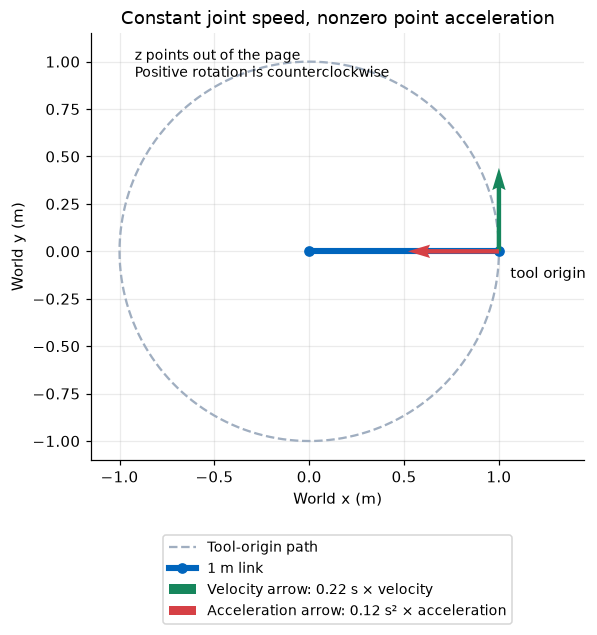

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
angle = np.linspace(0, 2*np.pi, 361)
ax.plot(np.cos(angle), np.sin(angle), "--", color="#A0AEC0", label="Tool-origin path")
ax.plot([0, 1], [0, 0], "o-", color="#0065BD", linewidth=4, label="1 m link")
ax.quiver(1, 0, 0, .22*2, angles="xy", scale_units="xy", scale=1,
          color="#16865C", zorder=5, width=.009, label="Velocity arrow: 0.22 s × velocity")
ax.quiver(1, 0, .12*(-4), 0, angles="xy", scale_units="xy", scale=1,
          color="#D64045", zorder=5, width=.009, label="Acceleration arrow: 0.12 s² × acceleration")
ax.annotate("tool origin", (1, 0), xytext=(1.06, -.14))
ax.text(-.92, .92, "z points out of the page\nPositive rotation is counterclockwise", fontsize=9)
ax.set(xlabel="World x (m)", ylabel="World y (m)", aspect="equal",
       xlim=(-1.15, 1.45), ylim=(-1.1, 1.15), title="Constant joint speed, nonzero point acceleration")
ax.grid(alpha=.25)
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.16), fontsize=9)
fig.tight_layout()
plt.show()

## API checklist and experiments

| Quantity | Initialization | Retrieval/conversion |
|---|---|---|
| $J_b,J_s,J_{\rm LWA}$ | `computeJointJacobians`; `updateFramePlacements` | `getFrameJacobian` with the requested convention |
| RPY analytic $J_{\rm a}$ | Obtain $R$ and a geometric Jacobian | `matrixToRpy`; `computeRpyJacobian(..., WORLD)`; solve for the angular rows |
| $\dot J$ | `computeJointJacobiansTimeVariation`; `updateFramePlacements` | `getFrameJacobianTimeVariation` with the same convention as $J$ |
| Spatial acceleration | `forwardKinematics(q, v, a)`; `updateFramePlacements` | `getFrameAcceleration` |
| Tool-origin acceleration in world axes | Same acceleration initialization | `getFrameClassicalAcceleration(..., LOCAL_WORLD_ALIGNED).linear` |
| Position-task bias $\dot J_pv$ | Same initialization with `a = 0` | Same classical-LWA linear block |

Try changing the arm's `q`, `v`, and `a`, then rerun the notebook. Compare the angular velocity with the two orientation-coordinate rate vectors. Move the pitch toward $\pi/2$ and inspect `np.linalg.cond(E_s)`; the chart check will deliberately stop the RPY conversion near gimbal lock. Change the one-link angular speed: the centripetal acceleration scales with its square, while its WORLD spatial acceleration remains zero at constant speed.

**References:** [Pinocchio reference frames](https://gepettoweb.laas.fr/doc/stack-of-tasks/pinocchio/master/doxygen-html/group__pinocchio__multibody.html), [roll–pitch–yaw Jacobians](https://gepettoweb.laas.fr/doc/stack-of-tasks/pinocchio/devel/doxygen-html/namespacepinocchio_1_1rpy.html), [frame algorithms](https://gepettoweb.laas.fr/doc/stack-of-tasks/pinocchio/devel/doxygen-html/frames_8hpp_source.html), and the [Pinocchio 3.9.0 implementation of spatial/classical acceleration](https://github.com/stack-of-tasks/pinocchio/blob/v3.9.0/include/pinocchio/algorithm/frames.hxx).

[Chapter 5 index](README.md) · [Earlier Jacobian and acceleration examples](01_jacobians_and_accelerations.ipynb) · [All chapters](../../README.md)